# Etapa 4. Indexación principal (B+Tree)

**Proyecto EDA 2026-2, Grupo 1, escenario B (comercio electrónico).**
Responsable de las etapas 3, 4 y 5: Carlos.

## Función de la etapa en el pipeline

La etapa 4 resuelve las **consultas por rango** del escenario B, por ejemplo "productos entre 10 y 20 dólares". La tabla hash de la etapa 3 responde consultas puntuales en O(1), pero no conserva el orden de las claves y no sirve para rangos. Un índice ordenado sí lo permite.

La estructura es un **B+Tree en disco** implementado a mano. El árbol vive en un archivo dividido en páginas de tamaño fijo y cada nodo ocupa una página. La clave es `(precio, parent_asin)` y el valor es la posición del registro en el catálogo en disco de la etapa 3. Las páginas leídas se guardan en un buffer pool, que es la caché LRU de la etapa 3. Un archivo ordenado con búsqueda binaria y una lista ordenada en memoria se usan como líneas base. El código de la etapa está en `src/etapa_4/bplustree.py`; el notebook lo importa y muestra cada parte junto a su explicación.

## Proceso

```
catálogo en disco (etapa 3)                 estado de productos (etapa 3)
   │                                            │
   ├─ 1. extraer (precio, parent_asin, offset, largo) de los productos con precio
   ├─ 2. ordenar con el merge sort de la etapa 1                      O(n log n)
   ├─ 3. carga masiva del B+Tree, página por página                    O(n)
   │                                            │
   │                                            └─ 4. insertar los productos con precio observado en el stream   O(log_B n)
   │
   ├─ consulta puntual: descenso raíz → hoja                           O(log_B n) lecturas
   └─ consulta por rango: descenso + recorrido de hojas enlazadas      O(log_B n + k / B) lecturas
   │
índice de precios en disco (etapas 5 y 9)
```

## Pasos del notebook

1. Configuración y entrada.
2. Estructura del B+Tree en disco.
3. Construcción del índice de precios.
4. Actualización del índice con el stream.
5. Consultas puntuales y por rango.
6. Experimentos de complejidad.
7. Salida de la etapa 4.

## Paso 1. Configuración y entrada

La etapa usa dos salidas de la etapa 3, que están en `data/interim/<CATEGORIA>/etapa_3/`.

- `catalogo.jsonl`, el catálogo en disco con el precio ya convertido a número.
- `estado_productos.parquet`, el estado de los productos con actividad en el stream, que incluye el precio observado en las compras.

La salida de la etapa se guarda en `data/interim/<CATEGORIA>/etapa_4/` y los resultados de los experimentos en `results/etapa_4/`. La celda muestra al final la plataforma y la semilla, que el enunciado pide reportar junto con los tiempos.

Los experimentos del paso 6 guardan sus resultados en `results/etapa_4/` y se reutilizan si existen. Para medir de nuevo se cambia `REEJECUTAR_EXPERIMENTOS` a `True`. Cada archivo de resultados guarda el procesador y la versión de Python con que se midió, y las figuras muestran esa plataforma aunque el notebook se ejecute en otra máquina.

In [1]:
import gc
import inspect
import json
import math
import platform
import random
import shutil
import struct
import sys
import time
import tracemalloc
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import psutil
import pyarrow.parquet as pq

# Raíz del proyecto: se sube de carpeta hasta encontrar la que contiene notebooks/ y data/
RAIZ = Path.cwd()
while not ((RAIZ / "notebooks").is_dir() and (RAIZ / "data").is_dir()) and RAIZ != RAIZ.parent:
    RAIZ = RAIZ.parent
sys.path.insert(0, str(RAIZ))       # para importar src/

from src import config
from src.etapa_3.storage import RUTA_CATALOGO, RUTA_ESTADOS, AlmacenCatalogo
from src.etapa_4.bplustree import (CAPACIDAD_BUFFER, CARPETA_ETAPA4, LLENADO_CARGA_MASIVA, RUTA_INDICE_PRECIO,
                                   TAM_PAGINA, ArbolBMas, bisect_izq, capacidad_hoja, capacidad_interno, clave,
                                   construir_indice_precio, leer_registro)

SEED = config.SEED
CATEGORIA = config.CATEGORIA
CARPETA_RESULTADOS = config.CARPETA_RESULTADOS / "etapa_4"
CARPETA_RESULTADOS.mkdir(parents=True, exist_ok=True)
CARPETA_ETAPA4.mkdir(parents=True, exist_ok=True)
assert RUTA_CATALOGO.exists() and RUTA_ESTADOS.exists(), \
    "Falta la salida de la etapa 3. Ejecutar antes notebooks/etapa3_almacenamiento_cache.ipynb"

# Las mediciones guardadas en results/etapa_4/ se reutilizan. Con True se miden de nuevo.
REEJECUTAR_EXPERIMENTOS = False

# Plataforma (el enunciado pide reportarla junto con la semilla)
PLATAFORMA = {
    "sistema": platform.platform(),
    "procesador": platform.processor() or platform.machine(),
    "nucleos": psutil.cpu_count(logical=True),
    "ram_gb": round(psutil.virtual_memory().total / 1e9, 1),
    "python": platform.python_version(),
    "semilla": SEED,
}


def ruta_relativa(ruta):
    return ruta.relative_to(RAIZ).as_posix()


def resultados(ruta, medir_tabla):
    """Lee la tabla de resultados si existe. Si no, la mide con medir_tabla() y la guarda.

    Cada tabla guarda el procesador y la versión de Python con que se midió.
    """
    if ruta.exists() and not REEJECUTAR_EXPERIMENTOS:
        print(f"Resultados leídos de {ruta_relativa(ruta)}")
        return pd.read_csv(ruta, dtype={"procesador": str, "python": str})
    tabla = medir_tabla().assign(procesador=PLATAFORMA["procesador"], python=PLATAFORMA["python"])
    tabla.to_csv(ruta, index=False)
    print(f"Resultados guardados en {ruta_relativa(ruta)}")
    return tabla


def plataforma_de(tabla):
    """Procesador y versión de Python con que se midió una tabla de resultados."""
    return f"{tabla['procesador'].iloc[0]}, Python {tabla['python'].iloc[0]}"


estados = pq.read_table(RUTA_ESTADOS).to_pandas()
print(f"Categoría: {CATEGORIA}")
print(f"Catálogo: {ruta_relativa(RUTA_CATALOGO)} ({RUTA_CATALOGO.stat().st_size / 1e6:,.0f} MB)")
print(f"Productos con estado en el stream: {len(estados):,}")
PLATAFORMA

Categoría: Office_Products
Catálogo: data/interim/Office_Products/etapa_3/catalogo.jsonl (303 MB)
Productos con estado en el stream: 195,019


{'sistema': 'Windows-10-10.0.19045-SP0',
 'procesador': 'AMD64 Family 23 Model 24 Stepping 1, AuthenticAMD',
 'nucleos': 8,
 'ram_gb': 32.1,
 'python': '3.12.0',
 'semilla': 42}

## Paso 2. Estructura del B+Tree en disco

Un B+Tree es un árbol de búsqueda balanceado en el que cada nodo tiene muchos hijos. Todas las entradas (clave, valor) están en las hojas, y cada hoja apunta a la siguiente. Los nodos internos solo guardan claves separadoras que guían el descenso. Todas las hojas están a la misma profundidad.

Se usa para índices en disco porque en ellos el costo dominante es el número de páginas leídas. Cada nodo ocupa una página completa, así que la altura del árbol es log_B n, donde B es el número de hijos por nodo. Una búsqueda binaria sobre un archivo ordenado necesita log₂ n lecturas. La celda siguiente calcula cuántas entradas caben con tres niveles y cuántas lecturas necesitaría la búsqueda binaria con ese número de entradas.

**Formato de página (4 096 bytes).**

| Página | Contenido | Tamaño |
| --- | --- | --- |
| 0, cabecera | Identificador, tamaño de página, raíz, número de páginas, número de claves, altura, primera hoja | 1 página |
| Hoja | Tipo, número de entradas, página de la hoja siguiente y entradas `(precio, asin, offset, largo)` | 11 + 30 bytes por entrada |
| Nodo interno | Tipo, número de claves, primer hijo y pares `(precio, asin, hijo)` | 11 + 26 bytes por clave |

`claves[i]` de un nodo interno es la menor clave del subárbol `hijos[i + 1]`. Para descender se busca con búsqueda binaria el primer separador mayor que la clave y se baja por el hijo correspondiente.

**Inserción.** Se desciende hasta la hoja y se inserta la entrada en orden. Si la hoja se llena, se divide en dos mitades, la nueva hoja se enlaza a continuación y su primera clave sube al padre. Si el padre se llena, también se divide y su clave central sube. Si se divide la raíz, el árbol crece un nivel. Cada división escribe O(1) páginas por nivel, así que una inserción cuesta O(log_B n).

**Carga masiva.** Con las entradas ya ordenadas, las hojas se escriben de izquierda a derecha al 90 % de su capacidad y luego se construye cada nivel interno sobre el anterior. Cada página se escribe una vez, así que la construcción cuesta O(n). El 10 % libre deja espacio para inserciones posteriores sin dividir de inmediato.

**Eliminación.** Se quita la entrada de su hoja sin fusionar nodos. Una hoja puede quedar con menos de la mitad de su capacidad, pero las búsquedas y los rangos siguen siendo correctos. El índice de precios casi no tiene eliminaciones, porque el catálogo no las genera, así que no se justifica el costo de la fusión.

**Buffer pool.** Las páginas leídas se guardan decodificadas en una `CacheLRU` de la etapa 3, con el número de página como clave y capacidad para 256 páginas, que en disco son 1 MB. En memoria ocupan más, porque cada página se guarda como objetos de Python; el paso 6 mide esa memoria. Las escrituras van directo al disco (*write-through*) y actualizan el buffer.

**Alternativas descartadas.**

- **Tabla hash.** La de la etapa 3 no conserva el orden de las claves, así que un rango obliga a revisar todas las entradas.
- **Archivo ordenado con búsqueda binaria.** Necesita log₂ n lecturas por consulta, y una inserción desplaza en promedio la mitad del archivo, O(n).
- **Árbol binario balanceado (AVL o rojo-negro).** Cuesta O(log₂ n) por operación. Guardado en disco con un nodo por página, leería log₂ n páginas por consulta. En memoria ocuparía O(n), como la lista ordenada.
- **B-Tree clásico.** Guarda valores también en los nodos internos, que admiten menos hijos por página, y un rango necesita un recorrido en orden que sube y baja por el árbol. En el B+Tree el rango recorre las hojas enlazadas con una lectura por hoja.

In [2]:
max_hoja, max_interno = capacidad_hoja(TAM_PAGINA), capacidad_interno(TAM_PAGINA)
por_hoja = int(max_hoja * LLENADO_CARGA_MASIVA)                 # entradas por hoja en la carga masiva
por_interno = int((max_interno + 1) * LLENADO_CARGA_MASIVA)     # hijos por nodo interno en la carga masiva
con_tres_niveles_llenos = (max_interno + 1) ** 2 * max_hoja
con_tres_niveles_carga = por_interno ** 2 * por_hoja
print(f"Páginas de {TAM_PAGINA} bytes: {max_hoja} entradas por hoja y {max_interno} claves ({max_interno + 1} hijos) "
      f"por nodo interno")
print(f"Carga masiva al {LLENADO_CARGA_MASIVA:.0%}: {por_hoja} entradas por hoja y {por_interno} hijos por nodo interno")
print(f"Entradas con tres niveles: {con_tres_niveles_llenos:,} con nodos llenos y {con_tres_niveles_carga:,} "
      f"con la carga masiva")
print(f"Lecturas de la búsqueda binaria con {con_tres_niveles_carga:,} entradas: "
      f"{math.ceil(math.log2(con_tres_niveles_carga))}")
print()
print(inspect.getsource(ArbolBMas._hoja_de))
print(inspect.getsource(ArbolBMas.insertar))
print(inspect.getsource(ArbolBMas._subir_separador))
print(inspect.getsource(ArbolBMas.carga_masiva))

Páginas de 4096 bytes: 136 entradas por hoja y 157 claves (158 hijos) por nodo interno
Carga masiva al 90%: 122 entradas por hoja y 142 hijos por nodo interno
Entradas con tres niveles: 3,395,104 con nodos llenos y 2,460,008 con la carga masiva
Lecturas de la búsqueda binaria con 2,460,008 entradas: 22

    def _hoja_de(self, k, camino=None):
        """Desciende desde la raíz hasta la hoja que debe contener k. Una lectura por nivel."""
        nodo = self._leer(self.raiz)
        while isinstance(nodo, Interno):
            i = bisect_der(nodo.claves, k)
            if camino is not None:
                camino.append((nodo, i))
            nodo = self._leer(nodo.hijos[i])
        return nodo

    def insertar(self, precio, asin, offset, largo):
        """Inserta la entrada o actualiza su valor si la clave ya existe."""
        k = clave(precio, asin)
        camino = []
        hoja = self._hoja_de(k, camino)
        i = bisect_izq(hoja.claves, k)
        if i < len(hoja.claves) and

## Paso 3. Construcción del índice de precios

Se recorre el catálogo de la etapa 3 y, para cada producto con precio, se obtiene la entrada `(precio, parent_asin, offset, largo)`. El offset y el largo indican dónde está el registro completo en `catalogo.jsonl`. Las entradas se ordenan con el merge sort propio de la etapa 1 y se cargan en el árbol con la carga masiva.

La clave incluye el `parent_asin` porque muchos productos comparten precio y las claves de un B+Tree deben ser únicas.

La construcción del índice real se mide una vez, porque es la operación de la etapa sobre el catálogo completo. Las mediciones con repeticiones están en el paso 6.

In [3]:
almacen = AlmacenCatalogo()
t0 = time.perf_counter()
arbol = construir_indice_precio()
t_construccion = time.perf_counter() - t0
ocupacion = arbol.ocupacion_hojas()
n_hojas = round(len(arbol) / (ocupacion * arbol.max_hoja))
altura_minima = 1 + math.ceil(math.log(n_hojas, arbol.max_interno + 1))
print(f"Entradas con precio de catálogo: {len(arbol):,} de {len(almacen):,} productos "
      f"({len(arbol) / len(almacen):.1%}); sin precio: {len(almacen) - len(arbol):,}")
print(f"Índice construido en {t_construccion:.1f} s, incluido el merge sort de {len(arbol):,} entradas")
print(f"Altura: {arbol.altura} (mínima posible con hojas llenas: {altura_minima})")
print(f"Páginas: {arbol.n_paginas:,} ({n_hojas:,} hojas), archivo de {arbol.tamano_bytes() / 1e6:.1f} MB")
print(f"Ocupación media de las hojas: {ocupacion:.1%}")
print(f"Páginas escritas: {arbol.escrituras:,}")

Entradas con precio de catálogo: 282,534 de 710,503 productos (39.8%); sin precio: 427,969
Índice construido en 11.4 s, incluido el merge sort de 282,534 entradas
Altura: 3 (mínima posible con hojas llenas: 3)
Páginas: 2,335 (2,316 hojas), archivo de 9.6 MB
Ocupación media de las hojas: 89.7%
Páginas escritas: 2,335


## Paso 4. Actualización del índice con el stream

Los productos sin precio en el catálogo no entran en la carga masiva. La etapa 3 registra el precio observado en las compras del stream. Los productos con precio observado que no tienen precio en el catálogo se insertan ahora en el índice, uno a uno, con la inserción en línea. Así el índice refleja lo que la etapa 3 aprendió del stream.

La posición del registro de cada producto se obtiene del índice hash de la etapa 3. Estas inserciones se miden una vez por la misma razón que la construcción; el costo por inserción con repeticiones está en el experimento C2.

In [4]:
en_indice = {a for _, a, _, _ in arbol}            # set solo para esta verificación
nuevos = estados[estados["precio_observado"].notna() & ~estados["parent_asin"].isin(en_indice)]

paginas_antes, escrituras_antes, altura_antes, entradas_antes = arbol.n_paginas, arbol.escrituras, arbol.altura, len(arbol)
t0 = time.perf_counter()
for asin, precio in zip(nuevos["parent_asin"], nuevos["precio_observado"]):
    offset, largo = almacen.indice.obtener(asin)
    arbol.insertar(precio, asin, offset, largo)
t_insercion = time.perf_counter() - t0

con_precio_observado = int(estados["precio_observado"].notna().sum())
print(f"Productos con precio observado en el stream: {con_precio_observado:,}")
print(f"  ya estaban en el índice por su precio de catálogo: {con_precio_observado - len(nuevos):,}")
print(f"  insertados ahora: {len(nuevos):,} en {t_insercion:.2f} s ({t_insercion / max(len(nuevos), 1) * 1e6:.0f} µs por inserción)")
print(f"Páginas nuevas por divisiones: {arbol.n_paginas - paginas_antes:,}   páginas escritas: {arbol.escrituras - escrituras_antes:,}")
print(f"Altura: {altura_antes} → {arbol.altura}   entradas en el índice: {entradas_antes:,} → {len(arbol):,} "
      f"({len(arbol) / entradas_antes - 1:.1%} más)")

Productos con precio observado en el stream: 191,404
  ya estaban en el índice por su precio de catálogo: 137,523
  insertados ahora: 53,881 en 13.94 s (259 µs por inserción)
Páginas nuevas por divisiones: 922   páginas escritas: 55,725
Altura: 3 → 3   entradas en el índice: 282,534 → 336,415 (19.1% más)


## Paso 5. Consultas puntuales y por rango

**Consulta puntual.** `buscar(precio, parent_asin)` desciende de la raíz a la hoja. Con el buffer pool vacío lee una página por nivel.

**Consulta por rango.** `rango(precio_min, precio_max)` desciende hasta la primera hoja del rango y recorre las hojas enlazadas hasta pasar `precio_max`. Lee la altura del árbol más una página por cada hoja recorrida.

Se reabre el índice desde el disco con un buffer pool vacío para contar las lecturas reales. Los rangos se ejecutan uno detrás de otro con el mismo buffer pool. El tiempo de las consultas se mide con repeticiones en el paso 6.

In [5]:
arbol.cerrar()
arbol = ArbolBMas(RUTA_INDICE_PRECIO)
catalogo = open(RUTA_CATALOGO, "rb")

asin_ejemplo = "B001S28Q4Q"
precio_ejemplo = almacen.leer(asin_ejemplo)["precio"]
antes = arbol.lecturas
posicion = arbol.buscar(precio_ejemplo, asin_ejemplo)
print(f"buscar({precio_ejemplo}, {asin_ejemplo!r}) → {posicion}, {arbol.lecturas - antes} páginas leídas "
      f"(altura {arbol.altura})")
print(f"Registro: {leer_registro(catalogo, *posicion)['title'][:80]}")

filas = []
for desde, hasta in [(9.99, 9.99), (10, 12), (10, 20), (100, 200), (1000, 50000)]:
    antes = arbol.lecturas
    resultado = list(arbol.rango(desde, hasta))
    filas.append({"rango": f"[{desde}, {hasta}]", "resultados": len(resultado),
                  "paginas_leidas": arbol.lecturas - antes,
                  "resultados_por_pagina": round(len(resultado) / max(arbol.lecturas - antes, 1), 1)})
pd.DataFrame(filas)

buscar(2.68, 'B001S28Q4Q') → (0, 438), 3 páginas leídas (altura 3)
Registro: Alliance Rubber 07706 Non-Latex Brites File Bands, Colored Elastic Bands, 1.5 oz


,rango,resultados,paginas_leidas,resultados_por_pagina
0,"[9.99, 9.99]",11218,93,120.6
1,"[10, 12]",25841,242,106.8
2,"[10, 20]",100715,723,139.3
3,"[100, 200]",11403,96,118.8
4,"[1000, 50000]",820,8,102.5


Las páginas leídas en cada rango son aproximadamente la altura más los resultados divididos por las entradas de cada hoja. El primer rango lee las páginas del descenso. Los siguientes leen menos páginas de descenso porque la raíz y algunos nodos internos ya están en el buffer pool, salvo después de un rango grande. Un recorrido largo llena el buffer pool LRU con hojas que no se volverán a usar y desaloja la raíz. Este efecto se conoce como inundación secuencial (*sequential flooding*) y es una limitación conocida de LRU en los gestores de bases de datos.

**Consulta combinada con la etapa 3.** El escenario B pide precio y disponibilidad. Se buscan los productos entre 10 y 12 dólares, se leen sus registros del catálogo y se combinan con el estado del stream de la etapa 3.

In [6]:
estado_por_asin = estados.set_index("parent_asin")
filas = []
for precio, asin, offset, largo in arbol.rango(10, 12):
    registro = leer_registro(catalogo, offset, largo)
    disponible = estado_por_asin["disponible"].get(asin, True)
    filas.append({"parent_asin": asin, "precio": precio, "title": registro["title"][:60],
                  "average_rating": registro["average_rating"], "rating_number": registro["rating_number"],
                  "compras_stream": estado_por_asin["compras"].get(asin, 0), "disponible": disponible})
resultado = pd.DataFrame(filas)
print(f"Productos entre 10 y 12 dólares: {len(resultado):,}   disponibles: {resultado['disponible'].sum():,}")
resultado[resultado["disponible"]].nlargest(10, "rating_number")

Productos entre 10 y 12 dólares: 25,841   disponibles: 25,552


,parent_asin,precio,title,average_rating,rating_number,compras_stream,disponible
13185,B0CCK27BSW,11.40,"Scotch Heavy Duty Packaging Tape, 1.88"" x 22.2...",4.8,92216,539,True
10431,B0B3MX7LVG,10.99,"EZlifego Double Sided Tape Heavy Duty, Extra L...",4.3,90934,2478,True
13232,B0B3R1KFYJ,11.42,Amazon Basics Clear Thermal Laminating Plastic...,4.8,73280,340,True
14110,B0BPBVNZFG,11.52,"Paper Mate Gel Pens InkJoy Pens, Medium Point,...",4.8,65865,731,True
2087,B0C6Q9RKNJ,10.43,"Zebra Pen Z-Grip Retractable Ballpoint Pen, Me...",4.6,64688,514,True
15823,B082F417S1,11.89,"Leather Desk Pad Protector,Mouse Pad,Office De...",4.7,62565,1414,True
3866,B0BZYTC1TT,10.73,"PILOT FriXion Clicker Erasable, Refillable & R...",4.7,45908,276,True
6423,B0CCZPDK47,10.98,5 Pack ID Badge Holder With Clip – Badge Reels...,4.6,45048,454,True
616,B09HCGZDHR,10.07,Highlighter - STABILO BOSS ORIGINAL Pastel - W...,4.8,39393,39,True
1999,B0BKMH88Z3,10.40,"EXPO Low Odor Dry Erase Markers, Fine Tip, Bla...",4.8,39108,216,True


## Paso 6. Experimentos de complejidad

### Diseño del experimento

Se hacen cinco experimentos y una medición de memoria con el `ArbolBMas` de `src/etapa_4/bplustree.py`, el mismo código que usa la etapa en los pasos 3 a 5.

| Experimento | Métodos | Complejidad esperada |
| --- | --- | --- |
| A. Consulta puntual | B+Tree en disco (propio), archivo ordenado con búsqueda binaria (en disco) y lista ordenada con búsqueda binaria (en memoria) | O(log_B n) lecturas frente a O(log₂ n) lecturas |
| B. Consulta por rango | B+Tree, lista ordenada y recorrido completo de la lista, con n = 1M | O(log_B n + k / B) lecturas; tiempo O(log n + k) frente a O(n) |
| C1. Construcción | Carga masiva y n inserciones en orden aleatorio | O(n) frente a O(n log_B n) |
| C2. Inserción en línea | Inserción en un B+Tree con n entradas | O(log_B n) por inserción |
| D. Tamaño de página | B+Tree con páginas de 256 B a 16 KB, con n = 1M | Altura log_B n, con B proporcional al tamaño de página |
| Memoria | B+Tree abierto, carga masiva y lista ordenada | O(capacidad del buffer) frente a O(n) |

**Medidas deterministas y tiempos.** Las lecturas de página por consulta, la altura, las páginas escritas y la ocupación de las hojas dependen solo de los datos y de la semilla. Son la evidencia principal de la complejidad de un índice en disco y no cambian con la máquina. Los tiempos dependen además de la máquina y de la caché de páginas del sistema operativo, que mantiene en memoria los archivos recién escritos. Por eso las diferencias en tiempo entre las estructuras en disco son menores que las diferencias en lecturas.

**Tamaños y repeticiones.**

- **Mediciones por bloque.** Las consultas puntuales (A), los rangos (B), la inserción en línea (C2) y las consultas por tamaño de página (D) miden un bloque fijo de operaciones por repetición. El costo de una repetición no depende de n, así que tienen 100 repeticiones en todos los tamaños, incluido 10M.
- **Construcciones.** La carga masiva tiene 100 repeticiones de 1K a 1M y una corrida con 10M. Las inserciones en orden aleatorio tienen 100 repeticiones con 1K y 10K, 15 con 100K y 3 con 1M. Cada inserción reescribe al menos una página, y una repetición con 1M tarda unos 3 minutos en esta ejecución, así que 100 repeticiones tomarían unas 5 horas. En los notebooks de las etapas 0 a 3, medir 100 repeticiones en todas las construcciones hasta 1M llevó la ejecución completa a una hora o más. La celda del experimento imprime el tiempo medido por repetición y cuánto tardarían 100.
- **Precisión.** Cada tabla de tiempos incluye el error relativo de la media, desviación / (promedio · √repeticiones). Muestra la precisión que se alcanza con el número de repeticiones de cada medición.
- **Inserciones con 10M.** Construir el árbol con 10M inserciones no se mide. Con el costo por inserción medido en 1M, una sola corrida tardaría al menos media hora, según la estimación que imprime la celda del experimento. El costo de insertar en un árbol de 10M entradas se mide en C2.

**Condiciones de medición.**

- **Entradas.** Sintéticas con la forma real. El precio es i // 7 / 100, de modo que cada precio se repite 7 veces, y el asin es `B` seguido de i con 9 dígitos. Se generan ya ordenadas, sin guardarlas todas en memoria.
- **Lecturas.** Se cuentan las lecturas de página del B+Tree y las lecturas de registro del archivo ordenado. Las lecturas sin buffer se miden con un buffer pool de una sola página. Las mediciones de tiempo de A, B y C2 usan el buffer pool de 256 páginas, y las de D, el de una página.
- **Reloj.** `time.perf_counter`, con el recolector de basura desactivado durante cada medición. La estructura medida se libera fuera del intervalo medido.
- **Archivos.** Los índices de prueba se escriben en `data/interim/<CATEGORIA>/etapa_4/experimentos/` y se borran al terminar.
- **Plataforma y semilla.** Las del paso 1. Cada archivo de resultados guarda el procesador y la versión de Python con que se midió.
- **Resultados.** Se guardan en `results/etapa_4/` y se reutilizan si existen.

In [7]:
TAMANOS = [1_000, 10_000, 100_000, 1_000_000]
N_UNICO = 10_000_000
TAMANOS_TODOS = TAMANOS + [N_UNICO]
REPETICIONES = 100
REPETICIONES_INSERCION = {1_000: 100, 10_000: 100, 100_000: 15, 1_000_000: 3}
BLOQUE_CONSULTAS = 1_000
CARPETA_EXPERIMENTOS = CARPETA_ETAPA4 / "experimentos"
CARPETA_EXPERIMENTOS.mkdir(parents=True, exist_ok=True)
REGISTRO = struct.Struct("<d10sqi")            # mismo formato que una entrada de hoja (30 bytes)
BMAS, ARCHIVO, LISTA = "B+Tree en disco (propio)", "archivo ordenado, búsqueda binaria", "lista ordenada en memoria"


def entrada_sintetica(i):
    return (i // 7) / 100, f"B{i:09d}", i * 30, 30


def entradas_sinteticas(n):
    for i in range(n):
        yield entrada_sintetica(i)


def construir_arbol(ruta, n, tam_pagina=TAM_PAGINA, capacidad_buffer=CAPACIDAD_BUFFER):
    arbol = ArbolBMas(ruta, tam_pagina=tam_pagina, capacidad_buffer=capacidad_buffer, crear=True)
    arbol.carga_masiva(entradas_sinteticas(n))
    return arbol


class ArchivoOrdenado:
    """Línea base en disco: registros de 30 bytes en orden de clave y búsqueda binaria con un seek por paso."""

    def __init__(self, ruta, n):
        with open(ruta, "wb") as archivo:
            for p, a, o, l in entradas_sinteticas(n):
                archivo.write(REGISTRO.pack(p, a.encode("ascii"), o, l))
        self.n = n
        self.archivo = open(ruta, "rb")
        self.lecturas = 0

    def buscar(self, precio, asin):
        k = clave(precio, asin)
        lo, hi = 0, self.n
        while lo < hi:
            medio = (lo + hi) // 2
            self.archivo.seek(medio * REGISTRO.size)
            p, a, o, l = REGISTRO.unpack(self.archivo.read(REGISTRO.size))
            self.lecturas += 1
            if (p, a) < k:
                lo = medio + 1
            elif (p, a) > k:
                hi = medio
            else:
                return o, l
        return None

    def cerrar(self):
        self.archivo.close()


class ListaOrdenada:
    """Línea base en memoria: claves y valores en dos listas ordenadas."""

    def __init__(self, n):
        self.claves, self.valores = [], []
        for p, a, o, l in entradas_sinteticas(n):
            self.claves.append(clave(p, a))
            self.valores.append((o, l))

    def buscar(self, precio, asin):
        k = clave(precio, asin)
        i = bisect_izq(self.claves, k)
        return self.valores[i] if i < len(self.claves) and self.claves[i] == k else None

    def rango(self, precio_min, precio_max):
        i = bisect_izq(self.claves, (float(precio_min), b""))
        j = bisect_izq(self.claves, (float(precio_max), b"\xff"))
        return list(zip(self.claves[i:j], self.valores[i:j]))


def consultar(estructura, consultas):
    for p, a in consultas:
        estructura.buscar(p, a)


def medir(funcion, *args, recolectar=True):
    """(segundos, resultado) de funcion(*args), con el recolector de basura desactivado.

    El resultado se devuelve para que la estructura se libere fuera del intervalo medido.
    """
    if recolectar:
        gc.collect()
    gc.disable()
    try:
        t0 = time.perf_counter()
        resultado = funcion(*args)
        segundos = time.perf_counter() - t0
    finally:
        gc.enable()
    return segundos, resultado


def medir_memoria(funcion, *args):
    """(resultado, memoria actual, memoria pico) en bytes. Solo se rastrea lo que asigna funcion."""
    gc.collect()
    tracemalloc.start()
    resultado = funcion(*args)
    actual, pico = tracemalloc.get_traced_memory()
    tracemalloc.stop()
    return resultado, actual, pico


def resumir(tabla, columnas=("metodo", "n")):
    """Promedio, desviación estándar y error relativo de la media del tiempo total y del tiempo por operación."""
    tabla = tabla.assign(us_por_operacion=tabla["segundos"] / tabla["operaciones"] * 1e6)
    resumen = (tabla.groupby(list(columnas), sort=False)
               .agg(promedio_s=("segundos", "mean"), desv_est_s=("segundos", "std"),
                    us_por_operacion=("us_por_operacion", "mean"), desv_us=("us_por_operacion", "std"),
                    repeticiones=("segundos", "count"))
               .reset_index())
    resumen["error_rel_media"] = resumen["desv_est_s"] / (resumen["promedio_s"] * np.sqrt(resumen["repeticiones"]))
    return resumen


def pendientes(resumen, valor, esperado, x="n", desde=None, hasta=None):
    """Pendiente log-log de valor frente a x, ajustada por mínimos cuadrados para cada método."""
    filas = []
    for metodo, datos in resumen.groupby("metodo", sort=False):
        if desde is not None:
            datos = datos[datos[x] >= desde]
        if hasta is not None:
            datos = datos[datos[x] <= hasta]
        k, _ = np.polyfit(np.log10(datos[x]), np.log10(datos[valor]), 1)
        filas.append({"metodo": metodo, "pendiente_empirica": round(k, 2), "esperado": esperado[metodo],
                      "rango": f"{datos[x].min():,.0f} a {datos[x].max():,.0f}"})
    return pd.DataFrame(filas)


def referencia(ax, x, base_x, base_y, forma, estilo, etiqueta):
    """Curva teórica anclada en el punto (base_x, base_y)."""
    x = np.array(x, dtype=float)
    ax.plot(x, base_y * forma(x) / forma(float(base_x)), estilo, lw=1, label=f"referencia {etiqueta}")


def ejes_loglog(ax, titulo, xlabel, ylabel):
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_title(titulo)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.legend(fontsize=8)


def limpiar_experimentos():
    for ruta in CARPETA_EXPERIMENTOS.iterdir():
        ruta.unlink()


# Las tres estructuras de A devuelven el mismo valor y None para una clave que no existe
n_prueba = 10_000
arbol_prueba = construir_arbol(CARPETA_EXPERIMENTOS / "prueba.bpt", n_prueba)
archivo_prueba = ArchivoOrdenado(CARPETA_EXPERIMENTOS / "prueba.bin", n_prueba)
lista_prueba = ListaOrdenada(n_prueba)
for p, a, o, l in (entrada_sintetica(i) for i in range(0, n_prueba, 37)):
    assert arbol_prueba.buscar(p, a) == archivo_prueba.buscar(p, a) == lista_prueba.buscar(p, a) == (o, l)
assert arbol_prueba.buscar(0.0, "B999999999") is archivo_prueba.buscar(0.0, "B999999999") is None
assert list(arbol_prueba.rango(1, 2)) == [(p, a.decode("ascii"), o, l) for (p, a), (o, l) in lista_prueba.rango(1, 2)]
arbol_prueba.cerrar()
archivo_prueba.cerrar()
del lista_prueba
limpiar_experimentos()
print("Las tres estructuras dan el resultado esperado.")

Las tres estructuras dan el resultado esperado.


### Experimento A. Consulta puntual

Para cada n se construyen el B+Tree, el archivo ordenado y la lista ordenada con las mismas entradas.

- **Lecturas sin buffer.** Se reabre el árbol con un buffer pool de una página y se hacen 200 consultas aleatorias, las mismas para el archivo ordenado. Las lecturas del B+Tree deben ser iguales a su altura, que crece como log_B n. Las del archivo ordenado deben crecer como log₂ n.
- **Tiempo.** Bloques de 1 000 consultas aleatorias con el buffer pool de 256 páginas. Con un costo O(log n), el tiempo por consulta debe crecer muy poco con n, con pendiente log-log cercana a 0. Cuando el árbol deja de caber en el buffer pool, las hojas se leen del archivo y se decodifican en cada consulta, y el tiempo sube.

In [8]:
def medir_a():
    filas = []
    ruta_arbol = CARPETA_EXPERIMENTOS / "a.bpt"
    for n in TAMANOS_TODOS:
        rng = random.Random(SEED + n)
        construir_arbol(ruta_arbol, n).cerrar()
        archivo_n = ArchivoOrdenado(CARPETA_EXPERIMENTOS / "ordenado.bin", n)
        lista_n = ListaOrdenada(n)

        # Lecturas sin buffer: árbol reabierto con una sola página de buffer
        muestra = [entrada_sintetica(rng.randrange(n))[:2] for _ in range(200)]
        with ArbolBMas(ruta_arbol, capacidad_buffer=1) as arbol_frio:
            consultar(arbol_frio, muestra)
            lecturas = {BMAS: arbol_frio.lecturas / len(muestra), LISTA: 0.0}
            altura, paginas = arbol_frio.altura, arbol_frio.n_paginas
        consultar(archivo_n, muestra)
        lecturas[ARCHIVO] = archivo_n.lecturas / len(muestra)

        arbol_n = ArbolBMas(ruta_arbol)
        estructuras = {BMAS: arbol_n, ARCHIVO: archivo_n, LISTA: lista_n}
        gc.collect()
        for rep in range(REPETICIONES):
            consultas = [entrada_sintetica(rng.randrange(n))[:2] for _ in range(BLOQUE_CONSULTAS)]
            for metodo, estructura in estructuras.items():
                segundos, _ = medir(consultar, estructura, consultas, recolectar=False)
                filas.append({"metodo": metodo, "n": n, "repeticion": rep, "operaciones": len(consultas),
                              "segundos": segundos, "lecturas_sin_buffer": lecturas[metodo],
                              "altura": altura, "paginas": paginas})
        arbol_n.cerrar()
        archivo_n.cerrar()
        del lista_n, estructuras
        limpiar_experimentos()
        print(f"n = {n:>10,} medido (altura {altura}, {lecturas[BMAS]:.2f} y {lecturas[ARCHIVO]:.2f} lecturas por consulta)")
    return pd.DataFrame(filas)


tiempos_a = resultados(CARPETA_RESULTADOS / "consulta_tiempos.csv", medir_a)
resumen_a = resumir(tiempos_a).merge(
    tiempos_a.groupby(["metodo", "n"], as_index=False, sort=False)[["lecturas_sin_buffer", "altura", "paginas"]].first(),
    on=["metodo", "n"])
resumen_a["log2_n"] = np.log2(resumen_a["n"])
# Sin buffer, el B+Tree lee exactamente una página por nivel
assert (resumen_a.loc[resumen_a["metodo"] == BMAS, "lecturas_sin_buffer"]
        == resumen_a.loc[resumen_a["metodo"] == BMAS, "altura"]).all()
resumen_a.round({"promedio_s": 6, "desv_est_s": 6, "us_por_operacion": 2, "desv_us": 2, "error_rel_media": 4,
                 "lecturas_sin_buffer": 2, "log2_n": 2})

Resultados leídos de results/etapa_4/consulta_tiempos.csv


,metodo,n,promedio_s,desv_est_s,us_por_operacion,desv_us,repeticiones,error_rel_media,lecturas_sin_buffer,altura,paginas,log2_n
0,B+Tree en disco (propio),1000,0.005770,0.000656,5.77,0.66,100,0.0114,2.00,2,11,9.97
1,"archivo ordenado, búsqueda binaria",1000,0.015755,0.001379,15.75,1.38,100,0.0088,8.88,2,11,9.97
2,lista ordenada en memoria,1000,0.002503,0.000328,2.50,0.33,100,0.0131,0.00,2,11,9.97
3,B+Tree en disco (propio),10000,0.007253,0.000863,7.25,0.86,100,0.0119,2.00,2,84,13.29
4,"archivo ordenado, búsqueda binaria",10000,0.033589,0.002502,33.59,2.50,100,0.0074,12.35,2,84,13.29
5,lista ordenada en memoria,10000,0.003878,0.000702,3.88,0.70,100,0.0181,0.00,2,84,13.29
6,B+Tree en disco (propio),100000,0.058814,0.013927,58.81,13.93,100,0.0237,3.00,3,828,16.61
7,"archivo ordenado, búsqueda binaria",100000,0.063189,0.006521,63.19,6.52,100,0.0103,15.86,3,828,16.61
8,lista ordenada en memoria,100000,0.005962,0.001473,5.96,1.47,100,0.0247,0.00,3,828,16.61
9,B+Tree en disco (propio),1000000,0.081793,0.005229,81.79,5.23,100,0.0064,3.00,3,8257,19.93


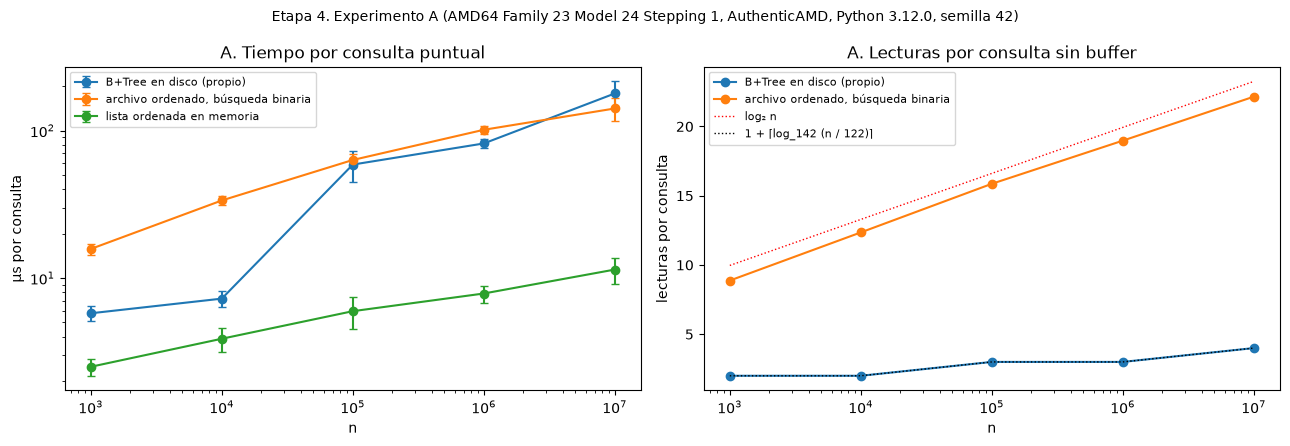

,metodo,pendiente_empirica,esperado,rango
0,B+Tree en disco (propio),0.40,≈0 (log_B n),"1,000 a 10,000,000"
1,"archivo ordenado, búsqueda binaria",0.24,≈0 (log₂ n),"1,000 a 10,000,000"
2,lista ordenada en memoria,0.16,≈0 (log₂ n),"1,000 a 10,000,000"


In [9]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))
for metodo, datos in resumen_a.groupby("metodo", sort=False):
    ax1.errorbar(datos["n"], datos["us_por_operacion"], yerr=datos["desv_us"], marker="o", capsize=3, label=metodo)
for metodo, datos in resumen_a[resumen_a["metodo"] != LISTA].groupby("metodo", sort=False):
    ax2.plot(datos["n"], datos["lecturas_sin_buffer"], marker="o", label=metodo)
n_ref = np.array(TAMANOS_TODOS, dtype=float)
ax2.plot(n_ref, np.log2(n_ref), "r:", lw=1, label="log₂ n")
ax2.plot(n_ref, 1 + np.ceil(np.log(n_ref / por_hoja) / np.log(por_interno)), "k:", lw=1,
         label=f"1 + ⌈log_{por_interno} (n / {por_hoja})⌉")
ejes_loglog(ax1, "A. Tiempo por consulta puntual", "n", "µs por consulta")
ax2.set_xscale("log")
ax2.set_xlabel("n")
ax2.set_ylabel("lecturas por consulta")
ax2.set_title("A. Lecturas por consulta sin buffer")
ax2.legend(fontsize=8)
plt.suptitle(f"Etapa 4. Experimento A ({plataforma_de(tiempos_a)}, semilla {SEED})", fontsize=10)
plt.tight_layout()
fig.savefig(CARPETA_RESULTADOS / "consulta.png", dpi=150)
plt.show()

pendientes(resumen_a, "us_por_operacion", {BMAS: "≈0 (log_B n)", ARCHIVO: "≈0 (log₂ n)", LISTA: "≈0 (log₂ n)"})

### Experimento B. Consulta por rango

Con n = 1M fijo se piden rangos que devuelven k = 10, 100, 1K, 10K y 100K resultados, en posiciones aleatorias. Como cada precio se repite 7 veces, el rango de k = 10 devuelve 7 resultados. Cada repetición es una consulta y cada k tiene 100 repeticiones.

El costo del B+Tree y de la lista ordenada es un descenso fijo más un término proporcional a k. Con k pequeño domina el descenso y con k grande el término lineal, así que la pendiente log-log debe acercarse a 1 solo con k grande. La celda ajusta la pendiente con todos los k y desde k = 1 000. El recorrido completo de la lista no depende de k, porque siempre revisa los n elementos.

Resultados leídos de results/etapa_4/rango_tiempos.csv


,metodo,k_objetivo,k,ms,desv_ms,error_rel_media,lecturas,hojas_esperadas,repeticiones
0,B+Tree en disco (propio),10,7.0,0.219,0.050,0.0227,1.0,0.1,100
1,lista ordenada en memoria,10,7.0,0.013,0.005,0.0423,0.0,NaN,100
2,recorrido completo de la lista,10,7.0,77.563,6.427,0.0083,0.0,NaN,100
3,B+Tree en disco (propio),100,98.0,0.328,0.090,0.0274,1.8,0.8,100
4,lista ordenada en memoria,100,98.0,0.058,0.359,0.6224,0.0,NaN,100
5,recorrido completo de la lista,100,98.0,88.289,14.709,0.0167,0.0,NaN,100
6,B+Tree en disco (propio),1000,994.0,1.252,0.318,0.0254,9.5,8.1,100
7,lista ordenada en memoria,1000,994.0,0.157,0.078,0.0497,0.0,NaN,100
8,recorrido completo de la lista,1000,994.0,87.309,7.602,0.0087,0.0,NaN,100
9,B+Tree en disco (propio),10000,9996.0,9.439,2.059,0.0218,81.6,81.9,100


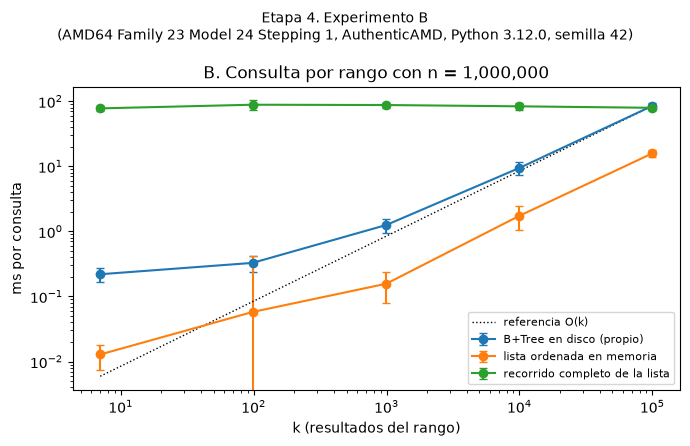

,metodo,pendiente_empirica,esperado,rango,ajuste
0,B+Tree en disco (propio),0.64,≈1 con k grande (log_B n + k),"7 a 99,995",todos los k
1,lista ordenada en memoria,0.74,≈1 con k grande (log₂ n + k),"7 a 99,995",todos los k
2,recorrido completo de la lista,-0.00,≈0 (n fijo),"7 a 99,995",todos los k
3,B+Tree en disco (propio),0.91,≈1 con k grande (log_B n + k),"994 a 99,995",desde k = 1 000
4,lista ordenada en memoria,1.00,≈1 con k grande (log₂ n + k),"994 a 99,995",desde k = 1 000
5,recorrido completo de la lista,-0.02,≈0 (n fijo),"994 a 99,995",desde k = 1 000


In [10]:
N_RANGO = 1_000_000
RESULTADOS_K = [10, 100, 1_000, 10_000, 100_000]
RECORRIDO = "recorrido completo de la lista"


def rango_arbol(arbol, desde, hasta):
    return sum(1 for _ in arbol.rango(desde, hasta))


def rango_lista(lista, desde, hasta):
    return len(lista.rango(desde, hasta))


def rango_recorrido(lista, desde, hasta):
    return sum(1 for p, _ in lista.claves if desde <= p <= hasta)


def medir_b():
    filas = []
    rng = random.Random(SEED)
    arbol_n = construir_arbol(CARPETA_EXPERIMENTOS / "b.bpt", N_RANGO)
    lista_n = ListaOrdenada(N_RANGO)
    metodos = {BMAS: (rango_arbol, arbol_n), LISTA: (rango_lista, lista_n), RECORRIDO: (rango_recorrido, lista_n)}
    gc.collect()
    for k in RESULTADOS_K:
        for rep in range(REPETICIONES):
            # k resultados: k / 7 precios consecutivos, porque cada precio se repite 7 veces
            inicio = rng.randrange(N_RANGO // 7 - k // 7)
            desde, hasta = inicio / 100, (inicio + k // 7 - 1) / 100
            esperado = rango_lista(lista_n, desde, hasta)
            for metodo, (funcion, estructura) in metodos.items():
                antes = getattr(estructura, "lecturas", 0)
                segundos, encontrados = medir(funcion, estructura, desde, hasta, recolectar=False)
                assert encontrados == esperado
                filas.append({"metodo": metodo, "k_objetivo": k, "k": esperado, "repeticion": rep, "operaciones": 1,
                              "segundos": segundos, "lecturas": getattr(estructura, "lecturas", 0) - antes})
        print(f"k = {k:>7,} medido")
    arbol_n.cerrar()
    del lista_n
    limpiar_experimentos()
    return pd.DataFrame(filas)


tiempos_b = resultados(CARPETA_RESULTADOS / "rango_tiempos.csv", medir_b)
resumen_b = resumir(tiempos_b, ("metodo", "k_objetivo")).merge(
    tiempos_b.groupby(["metodo", "k_objetivo"], as_index=False, sort=False)[["k", "lecturas"]].mean(),
    on=["metodo", "k_objetivo"])
resumen_b["ms"] = resumen_b["promedio_s"] * 1e3
resumen_b["desv_ms"] = resumen_b["desv_est_s"] * 1e3
resumen_b["hojas_esperadas"] = np.where(resumen_b["metodo"] == BMAS, resumen_b["k"] / por_hoja, np.nan)
display(resumen_b[["metodo", "k_objetivo", "k", "ms", "desv_ms", "error_rel_media", "lecturas", "hojas_esperadas",
                   "repeticiones"]].round({"k": 0, "ms": 3, "desv_ms": 3, "error_rel_media": 4, "lecturas": 1,
                                           "hojas_esperadas": 1}))

fig, ax = plt.subplots(figsize=(7, 4.5))
for metodo, datos in resumen_b.groupby("metodo", sort=False):
    ax.errorbar(datos["k"], datos["ms"], yerr=datos["desv_ms"], marker="o", capsize=3, label=metodo)
base = resumen_b[resumen_b["metodo"] == BMAS].iloc[-1]
referencia(ax, resumen_b["k"].unique(), base["k"], base["ms"], lambda k: k, "k:", "O(k)")
ejes_loglog(ax, f"B. Consulta por rango con n = {N_RANGO:,}", "k (resultados del rango)", "ms por consulta")
plt.suptitle(f"Etapa 4. Experimento B\n({plataforma_de(tiempos_b)}, semilla {SEED})", fontsize=10)
plt.tight_layout()
fig.savefig(CARPETA_RESULTADOS / "rango.png", dpi=150)
plt.show()

esperado_b = {BMAS: "≈1 con k grande (log_B n + k)", LISTA: "≈1 con k grande (log₂ n + k)", RECORRIDO: "≈0 (n fijo)"}
pd.concat([pendientes(resumen_b, "ms", esperado_b, x="k").assign(ajuste="todos los k"),
           pendientes(resumen_b[resumen_b["k_objetivo"] >= 1_000], "ms", esperado_b, x="k")
           .assign(ajuste="desde k = 1 000")],
          ignore_index=True)

### Experimento C1. Construcción

Se compara la carga masiva con n inserciones en orden aleatorio. La carga masiva debe tener pendiente log-log cercana a 1. Las inserciones deben crecer como n log_B n, con pendiente algo mayor que 1, y escribir más páginas, porque cada inserción reescribe su hoja y las divisiones reescriben también el padre. Además se compara la ocupación de las hojas. La carga masiva las deja al 90 %. Con inserciones aleatorias la ocupación esperada es ln 2 ≈ 69 % (Yao, 1978).

Las páginas escritas, la altura y la ocupación no dependen de la máquina. La ocupación se calcula una vez por tamaño y método, porque recorrer todas las hojas no forma parte de la construcción.

In [11]:
MASIVA, INSERCIONES = "carga masiva", "inserciones en orden aleatorio"


def insertar_aleatorio(ruta, orden):
    arbol = ArbolBMas(ruta, crear=True)
    for i in orden:
        arbol.insertar(*entrada_sintetica(i))
    return arbol


def medir_c1():
    filas = []
    ruta = CARPETA_EXPERIMENTOS / "c.bpt"

    def registrar(metodo, n, rep, segundos, arbol_n):
        filas.append({"metodo": metodo, "n": n, "repeticion": rep, "operaciones": n, "segundos": segundos,
                      "paginas_escritas": arbol_n.escrituras, "altura": arbol_n.altura,
                      "ocupacion": arbol_n.ocupacion_hojas() if rep == 0 else np.nan})
        arbol_n.cerrar()

    for n in TAMANOS_TODOS:
        for rep in range(REPETICIONES if n <= TAMANOS[-1] else 1):
            segundos, arbol_n = medir(construir_arbol, ruta, n)
            registrar(MASIVA, n, rep, segundos, arbol_n)
        if n in REPETICIONES_INSERCION:
            orden = list(range(n))
            random.Random(SEED).shuffle(orden)
            for rep in range(REPETICIONES_INSERCION[n]):
                segundos, arbol_n = medir(insertar_aleatorio, ruta, orden)
                registrar(INSERCIONES, n, rep, segundos, arbol_n)
            del orden
        limpiar_experimentos()
        print(f"n = {n:>10,} medido")
    return pd.DataFrame(filas)


tiempos_c1 = resultados(CARPETA_RESULTADOS / "construccion_tiempos.csv", medir_c1)
resumen_c1 = resumir(tiempos_c1).merge(
    tiempos_c1.groupby(["metodo", "n"], as_index=False, sort=False)
    .agg(paginas_escritas=("paginas_escritas", "mean"), altura=("altura", "first"), ocupacion=("ocupacion", "first")),
    on=["metodo", "n"])
resumen_c1["escrituras_por_entrada"] = resumen_c1["paginas_escritas"] / resumen_c1["n"]

# Justificación de las repeticiones: tiempo de una repetición y de 100 donde se hicieron menos
for _, fila in resumen_c1[resumen_c1["repeticiones"] < REPETICIONES].iterrows():
    print(f"{fila['metodo']}, n = {fila['n']:,}: {fila['repeticiones']} repeticiones de {fila['promedio_s']:.1f} s; "
          f"100 tomarían {100 * fila['promedio_s'] / 60:.0f} min")
por_insercion_1m = resumen_c1.loc[(resumen_c1["metodo"] == INSERCIONES) & (resumen_c1["n"] == TAMANOS[-1]),
                                  "us_por_operacion"].item()
print(f"Construir el árbol con {N_UNICO:,} inserciones, al costo por inserción medido en 1M "
      f"({por_insercion_1m:.0f} µs), tomaría al menos {N_UNICO * por_insercion_1m / 1e6 / 60:.0f} min en una sola "
      f"corrida, porque el costo por inserción crece con n")
resumen_c1.round({"promedio_s": 4, "desv_est_s": 4, "us_por_operacion": 2, "desv_us": 2, "error_rel_media": 4,
                  "paginas_escritas": 0, "ocupacion": 3, "escrituras_por_entrada": 4})

Resultados leídos de results/etapa_4/construccion_tiempos.csv
inserciones en orden aleatorio, n = 100,000: 15 repeticiones de 9.1 s; 100 tomarían 15 min
inserciones en orden aleatorio, n = 1,000,000: 3 repeticiones de 184.3 s; 100 tomarían 307 min
carga masiva, n = 10,000,000: 1 repeticiones de 22.3 s; 100 tomarían 37 min
Construir el árbol con 10,000,000 inserciones, al costo por inserción medido en 1M (184 µs), tomaría al menos 31 min en una sola corrida, porque el costo por inserción crece con n


,metodo,n,promedio_s,desv_est_s,us_por_operacion,desv_us,repeticiones,error_rel_media,paginas_escritas,altura,ocupacion,escrituras_por_entrada
0,carga masiva,1000,0.0025,0.0006,2.47,0.58,100,0.0233,11.0,2,0.817,0.0110
1,inserciones en orden aleatorio,1000,0.0367,0.0028,36.67,2.75,100,0.0075,1019.0,2,0.735,1.0190
2,carga masiva,10000,0.0169,0.0016,1.69,0.16,100,0.0096,84.0,2,0.897,0.0084
3,inserciones en orden aleatorio,10000,0.5054,0.0794,50.54,7.94,100,0.0157,10215.0,2,0.681,1.0215
4,carga masiva,100000,0.1723,0.0133,1.72,0.13,100,0.0077,828.0,3,0.897,0.0083
5,inserciones en orden aleatorio,100000,9.1360,0.3076,91.36,3.08,15,0.0087,102151.0,3,0.688,1.0215
6,carga masiva,1000000,1.8950,0.1812,1.89,0.18,100,0.0096,8257.0,3,0.897,0.0083
7,inserciones en orden aleatorio,1000000,184.2672,21.6776,184.27,21.68,3,0.0679,1021645.0,3,0.687,1.0216
8,carga masiva,10000000,22.3279,NaN,2.23,NaN,1,NaN,82553.0,4,0.897,0.0083


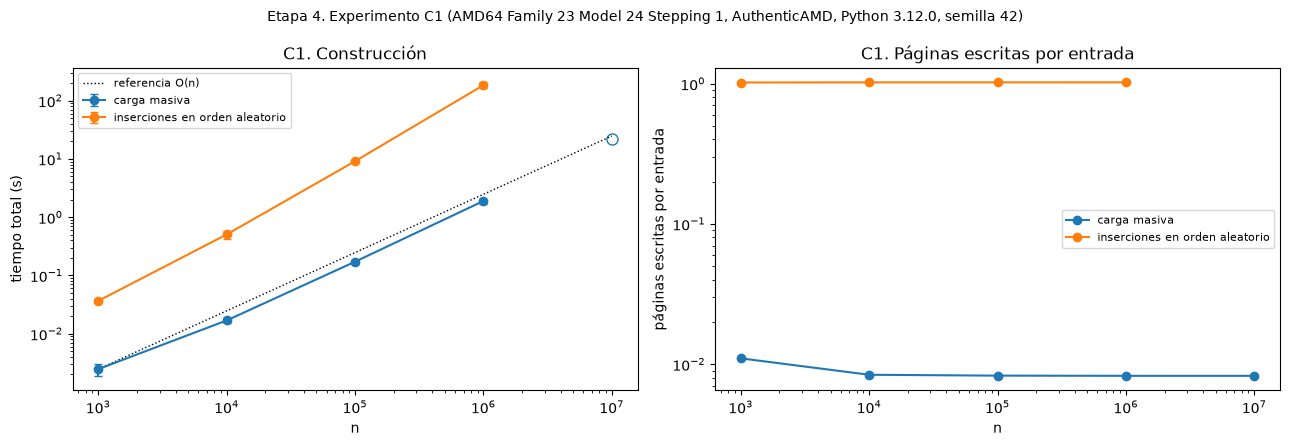

,metodo,pendiente_empirica,esperado,rango
0,carga masiva,0.97,≈1 (n),"1,000 a 1,000,000"
1,inserciones en orden aleatorio,1.24,>1 (n log_B n),"1,000 a 1,000,000"


In [12]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))
for metodo, datos in resumen_c1.groupby("metodo", sort=False):
    repetidas = datos[datos["repeticiones"] > 1]
    barras = ax1.errorbar(repetidas["n"], repetidas["promedio_s"], yerr=repetidas["desv_est_s"], marker="o",
                          capsize=3, label=metodo)
    unica = datos[datos["repeticiones"] == 1]
    ax1.plot(unica["n"], unica["promedio_s"], marker="o", markerfacecolor="none", markersize=8, linestyle="none",
             color=barras[0].get_color())
    ax2.plot(datos["n"], datos["escrituras_por_entrada"], marker="o", label=metodo)
base = resumen_c1[resumen_c1["metodo"] == MASIVA].iloc[0]
referencia(ax1, TAMANOS_TODOS, base["n"], base["promedio_s"], lambda n: n, "k:", "O(n)")
ejes_loglog(ax1, "C1. Construcción", "n", "tiempo total (s)")
ejes_loglog(ax2, "C1. Páginas escritas por entrada", "n", "páginas escritas por entrada")
plt.suptitle(f"Etapa 4. Experimento C1 ({plataforma_de(tiempos_c1)}, semilla {SEED})", fontsize=10)
plt.tight_layout()
fig.savefig(CARPETA_RESULTADOS / "construccion.png", dpi=150)
plt.show()

pendientes(resumen_c1, "promedio_s", {MASIVA: "≈1 (n)", INSERCIONES: ">1 (n log_B n)"}, hasta=TAMANOS[-1])

### Experimento C2. Inserción en línea

Es la operación que usa la etapa en el paso 4. Para cada n se construye el árbol con la carga masiva y se insertan entradas nuevas en posiciones aleatorias. Cada entrada nueva tiene el precio de una entrada existente elegida al azar y un asin que empieza con `C`, así que no repite ninguna clave. Cada repetición inserta un bloque de min(1 000, n / 1 000) entradas, de modo que en las 100 repeticiones el árbol crece como mucho un 10 %. El costo por inserción debe ser O(log_B n), con pendiente log-log cercana a 0. Las páginas escritas por inserción no dependen de la máquina.

Resultados leídos de results/etapa_4/insercion_tiempos.csv


,metodo,n,promedio_s,desv_est_s,us_por_operacion,desv_us,repeticiones,error_rel_media,insertadas,paginas_escritas,paginas_nuevas,entradas_al_terminar,altura,crecimiento,escrituras_por_insercion
0,B+Tree en disco (propio),1000,0.000076,0.000037,75.64,36.89,100,0.0488,100,106,3,1100,2,0.10,1.060
1,B+Tree en disco (propio),10000,0.000900,0.000376,89.96,37.60,100,0.0418,1000,1036,18,11000,2,0.10,1.036
2,B+Tree en disco (propio),100000,0.018973,0.007501,189.73,75.01,100,0.0395,10000,10424,212,110000,3,0.10,1.042
3,B+Tree en disco (propio),1000000,0.183727,0.021637,183.73,21.64,100,0.0118,100000,104212,2106,1100000,3,0.10,1.042
4,B+Tree en disco (propio),10000000,0.275645,0.014512,275.64,14.51,100,0.0053,100000,100000,0,10100000,4,0.01,1.000


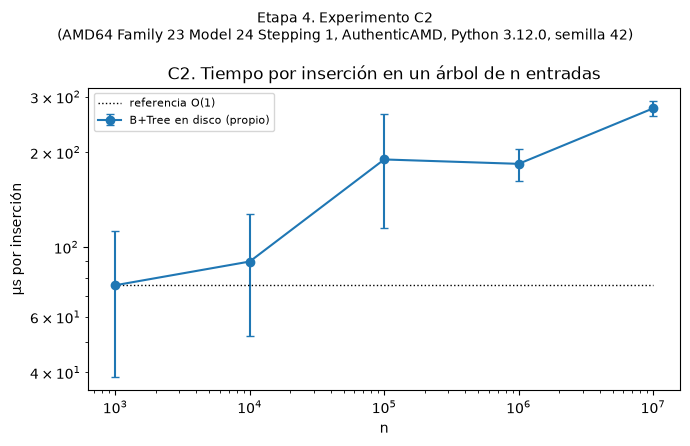

,metodo,pendiente_empirica,esperado,rango
0,B+Tree en disco (propio),0.14,≈0 (log_B n),"1,000 a 10,000,000"


In [13]:
def bloque_insercion(n):
    return min(1_000, n // 1_000)


def entradas_nuevas(n, rep):
    """Entradas con el precio de una entrada existente y un asin que empieza con C."""
    rng = random.Random(SEED + n + rep)
    nuevas = []
    for _ in range(bloque_insercion(n)):
        precio = (rng.randrange(n) // 7) / 100
        nuevas.append((precio, f"C{rng.randrange(10**9):09d}", 0, 30))
    return nuevas


def insertar_bloque(arbol, entradas):
    for e in entradas:
        arbol.insertar(*e)


def medir_c2():
    filas = []
    ruta = CARPETA_EXPERIMENTOS / "c2.bpt"
    for n in TAMANOS_TODOS:
        arbol_n = construir_arbol(ruta, n)
        bloques = [entradas_nuevas(n, rep) for rep in range(REPETICIONES)]
        gc.collect()
        for rep, bloque in enumerate(bloques):
            escrituras, paginas = arbol_n.escrituras, arbol_n.n_paginas
            segundos, _ = medir(insertar_bloque, arbol_n, bloque, recolectar=False)
            filas.append({"metodo": BMAS, "n": n, "repeticion": rep, "operaciones": len(bloque), "segundos": segundos,
                          "paginas_escritas": arbol_n.escrituras - escrituras, "paginas_nuevas": arbol_n.n_paginas - paginas,
                          "entradas_al_terminar": len(arbol_n), "altura": arbol_n.altura})
        arbol_n.cerrar()
        limpiar_experimentos()
        print(f"n = {n:>10,} medido")
    return pd.DataFrame(filas)


tiempos_c2 = resultados(CARPETA_RESULTADOS / "insercion_tiempos.csv", medir_c2)
resumen_c2 = resumir(tiempos_c2).merge(
    tiempos_c2.groupby(["metodo", "n"], as_index=False, sort=False)
    .agg(insertadas=("operaciones", "sum"), paginas_escritas=("paginas_escritas", "sum"),
         paginas_nuevas=("paginas_nuevas", "sum"), entradas_al_terminar=("entradas_al_terminar", "last"),
         altura=("altura", "last")),
    on=["metodo", "n"])
resumen_c2["crecimiento"] = resumen_c2["insertadas"] / resumen_c2["n"]
resumen_c2["escrituras_por_insercion"] = resumen_c2["paginas_escritas"] / resumen_c2["insertadas"]
display(resumen_c2.round({"promedio_s": 6, "desv_est_s": 6, "us_por_operacion": 2, "desv_us": 2,
                          "error_rel_media": 4, "crecimiento": 3, "escrituras_por_insercion": 3}))

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.errorbar(resumen_c2["n"], resumen_c2["us_por_operacion"], yerr=resumen_c2["desv_us"], marker="o", capsize=3,
            label=BMAS)
base = resumen_c2.iloc[0]
referencia(ax, TAMANOS_TODOS, base["n"], base["us_por_operacion"], lambda n: n ** 0, "k:", "O(1)")
ejes_loglog(ax, "C2. Tiempo por inserción en un árbol de n entradas", "n", "µs por inserción")
plt.suptitle(f"Etapa 4. Experimento C2\n({plataforma_de(tiempos_c2)}, semilla {SEED})", fontsize=10)
plt.tight_layout()
fig.savefig(CARPETA_RESULTADOS / "insercion.png", dpi=150)
plt.show()

pendientes(resumen_c2, "us_por_operacion", {BMAS: "≈0 (log_B n)"})

### Experimento D. Tamaño de página

Con n = 1M fijo se construye el árbol con páginas de 256 B a 16 KB. Una página más grande admite más claves por nodo (B mayor) y reduce la altura y las lecturas por consulta. A cambio, cada página leída tiene más bytes que transferir y decodificar. Se miden la altura, las lecturas y el tiempo por consulta sin buffer (buffer pool de una página) con 100 repeticiones de 1 000 consultas, y el tamaño del archivo.

Resultados leídos de results/etapa_4/pagina.csv


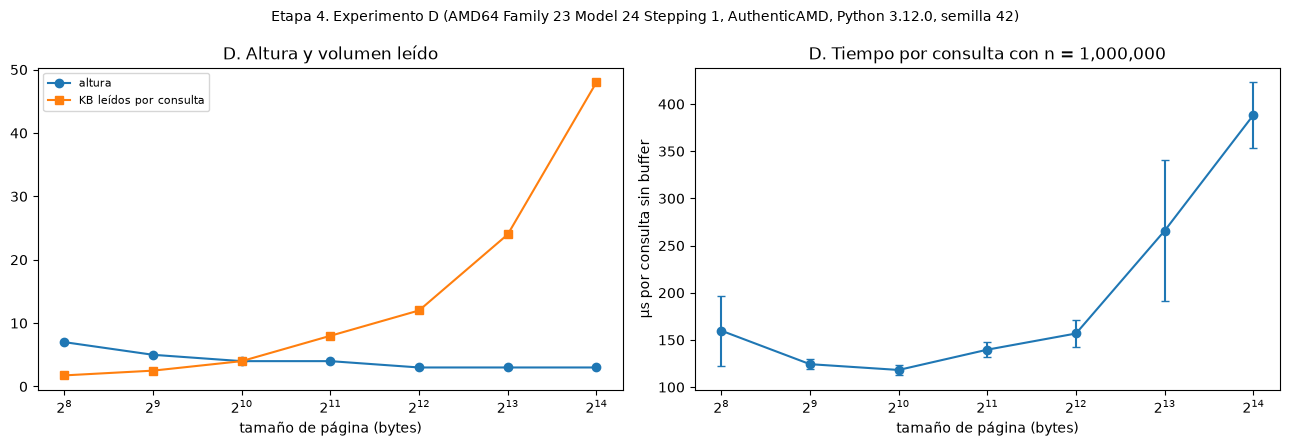

,tam_pagina,claves_por_interno,altura,lecturas_por_consulta,us_por_operacion,desv_us,error_rel_media,repeticiones,mb_archivo,kb_leidos_por_consulta
0,256,9,7,7.0,159.8,37.2,0.0233,100,41.1,1.8
1,512,19,5,5.0,124.3,5.1,0.0041,100,38.7,2.5
2,1024,38,4,4.0,118.2,5.8,0.0049,100,36.4,4.0
3,2048,78,4,4.0,139.7,7.9,0.0056,100,34.6,8.0
4,4096,157,3,3.0,156.8,13.8,0.0088,100,33.8,12.0
5,8192,314,3,3.0,265.8,74.9,0.0282,100,33.7,24.0
6,16384,629,3,3.0,388.4,34.6,0.0089,100,33.5,48.0


In [14]:
TAMANOS_PAGINA = [256, 512, 1024, 2048, 4096, 8192, 16384]
N_PAGINA = 1_000_000


def medir_d():
    filas = []
    rng = random.Random(SEED)
    ruta = CARPETA_EXPERIMENTOS / "d.bpt"
    for tam in TAMANOS_PAGINA:
        construir_arbol(ruta, N_PAGINA, tam_pagina=tam).cerrar()
        arbol_n = ArbolBMas(ruta, capacidad_buffer=1)
        gc.collect()
        for rep in range(REPETICIONES):
            consultas = [entrada_sintetica(rng.randrange(N_PAGINA))[:2] for _ in range(BLOQUE_CONSULTAS)]
            antes = arbol_n.lecturas
            segundos, _ = medir(consultar, arbol_n, consultas, recolectar=False)
            filas.append({"metodo": BMAS, "tam_pagina": tam, "repeticion": rep, "operaciones": len(consultas),
                          "segundos": segundos, "lecturas_por_consulta": (arbol_n.lecturas - antes) / len(consultas),
                          "altura": arbol_n.altura, "claves_por_interno": arbol_n.max_interno,
                          "mb_archivo": arbol_n.tamano_bytes() / 1e6})
        arbol_n.cerrar()
        limpiar_experimentos()
        print(f"página de {tam:>6,} bytes medida")
    return pd.DataFrame(filas)


tiempos_d = resultados(CARPETA_RESULTADOS / "pagina.csv", medir_d)
resumen_d = resumir(tiempos_d, ("tam_pagina",)).merge(
    tiempos_d.groupby("tam_pagina", as_index=False)
    .agg(claves_por_interno=("claves_por_interno", "first"), altura=("altura", "first"),
         lecturas_por_consulta=("lecturas_por_consulta", "mean"), mb_archivo=("mb_archivo", "first")),
    on="tam_pagina")
resumen_d["kb_leidos_por_consulta"] = resumen_d["lecturas_por_consulta"] * resumen_d["tam_pagina"] / 1024

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))
ax1.plot(resumen_d["tam_pagina"], resumen_d["altura"], marker="o", label="altura")
ax1.plot(resumen_d["tam_pagina"], resumen_d["kb_leidos_por_consulta"], marker="s", label="KB leídos por consulta")
ax1.set_xscale("log", base=2)
ax1.set_xlabel("tamaño de página (bytes)")
ax1.set_title("D. Altura y volumen leído")
ax1.legend(fontsize=8)
ax2.errorbar(resumen_d["tam_pagina"], resumen_d["us_por_operacion"], yerr=resumen_d["desv_us"], marker="o", capsize=3)
ax2.set_xscale("log", base=2)
ax2.set_xlabel("tamaño de página (bytes)")
ax2.set_ylabel("µs por consulta sin buffer")
ax2.set_title(f"D. Tiempo por consulta con n = {N_PAGINA:,}")
plt.suptitle(f"Etapa 4. Experimento D ({plataforma_de(tiempos_d)}, semilla {SEED})", fontsize=10)
plt.tight_layout()
fig.savefig(CARPETA_RESULTADOS / "pagina.png", dpi=150)
plt.show()

resumen_d[["tam_pagina", "claves_por_interno", "altura", "lecturas_por_consulta", "us_por_operacion", "desv_us",
           "error_rel_media", "repeticiones", "mb_archivo", "kb_leidos_por_consulta"]].round(
    {"lecturas_por_consulta": 2, "us_por_operacion": 1, "desv_us": 1, "error_rel_media": 4, "mb_archivo": 1,
     "kb_leidos_por_consulta": 1})

### Memoria actual y pico

Se mide con `tracemalloc` en tres situaciones, de 1K a 10M.

- **Carga masiva.** La memoria actual es la del árbol recién construido, con su buffer pool. La pico incluye la lista con la primera clave y la página de cada hoja, que la carga masiva guarda para construir los niveles internos y que tiene n / B elementos.
- **B+Tree abierto.** Se abre el árbol desde el disco y se hacen 1 000 consultas. Solo mantiene en memoria su buffer pool, así que su memoria debe dejar de crecer cuando el buffer pool se llena.
- **Lista ordenada.** Guarda todas las claves y valores en memoria y debe crecer linealmente con n.

Resultados leídos de results/etapa_4/memoria.csv


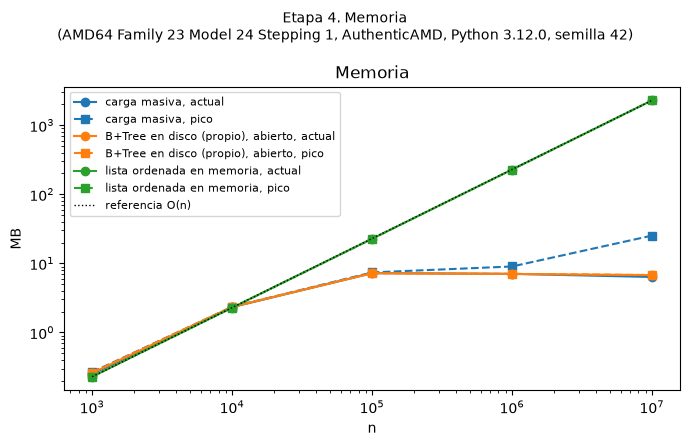

actual_mb               \
metodo   B+Tree en disco (propio), abierto carga masiva   
n                                                         
1000                                  0.26         0.25   
10000                                 2.34         2.32   
100000                                7.20         7.22   
1000000                               7.02         7.05   
10000000                              6.75         6.35   

                                                             pico_mb  \
metodo   lista ordenada en memoria B+Tree en disco (propio), abierto   
n                                                                      
1000                          0.23                              0.26   
10000                         2.28                              2.35   
100000                       22.70                              7.22   
1000000                     227.90                              7.05   
10000000                   2288.19                              6.78   

                                                 
metodo   carga masiva lista ordenada en memoria  
n                                                
1000             0.27                      0.23  
10000            2.34                      2.28  
100000           7.39                     22.70  
1000000          9.01                    227.90  
10000000        25.23                   2288.19

In [15]:
def abrir_y_consultar(ruta, consultas):
    arbol = ArbolBMas(ruta)
    consultar(arbol, consultas)
    return arbol


def medir_memoria_4():
    filas = []
    ruta = CARPETA_EXPERIMENTOS / "m.bpt"
    for n in TAMANOS_TODOS:
        arbol_m, actual, pico = medir_memoria(construir_arbol, ruta, n)
        arbol_m.cerrar()
        filas.append({"metodo": MASIVA, "n": n, "actual_mb": actual / 1e6, "pico_mb": pico / 1e6})
        consultas = [entrada_sintetica(i)[:2] for i in random.Random(SEED).sample(range(n), 1_000)]
        arbol_m, actual, pico = medir_memoria(abrir_y_consultar, ruta, consultas)
        arbol_m.cerrar()
        filas.append({"metodo": f"{BMAS}, abierto", "n": n, "actual_mb": actual / 1e6, "pico_mb": pico / 1e6})
        lista_m, actual, pico = medir_memoria(ListaOrdenada, n)
        del lista_m
        filas.append({"metodo": LISTA, "n": n, "actual_mb": actual / 1e6, "pico_mb": pico / 1e6})
        limpiar_experimentos()
        print(f"n = {n:>10,} medido")
    return pd.DataFrame(filas)


memoria = resultados(CARPETA_RESULTADOS / "memoria.csv", medir_memoria_4)
memoria["bytes_por_entrada_actual"] = memoria["actual_mb"] * 1e6 / memoria["n"]

fig, ax = plt.subplots(figsize=(7, 4.5))
for metodo, datos in memoria.groupby("metodo", sort=False):
    linea = ax.plot(datos["n"], datos["actual_mb"], marker="o", label=f"{metodo}, actual")
    ax.plot(datos["n"], datos["pico_mb"], marker="s", linestyle="--", color=linea[0].get_color(), label=f"{metodo}, pico")
base = memoria[memoria["metodo"] == LISTA].iloc[0]
referencia(ax, TAMANOS_TODOS, base["n"], base["actual_mb"], lambda n: n, "k:", "O(n)")
ejes_loglog(ax, "Memoria", "n", "MB")
plt.suptitle(f"Etapa 4. Memoria\n({plataforma_de(memoria)}, semilla {SEED})", fontsize=10)
plt.tight_layout()
fig.savefig(CARPETA_RESULTADOS / "memoria.png", dpi=150)
plt.show()

memoria.pivot(index="n", columns="metodo", values=["actual_mb", "pico_mb"]).round(2)

### Verificación del protocolo

La celda comprueba que cada medición de tiempo guardada tiene las repeticiones del diseño. Son 100 en las mediciones por bloque y en la carga masiva hasta 1M, una en la carga masiva con 10M y las de `REPETICIONES_INSERCION` en las inserciones en orden aleatorio.

In [16]:
def comprobar(tabla, columnas, esperado):
    """Cada combinación tiene el número de repeticiones que indica esperado(fila)."""
    for clave_grupo, repeticiones in tabla.groupby(columnas)["segundos"].count().items():
        fila = dict(zip(columnas, clave_grupo if isinstance(clave_grupo, tuple) else (clave_grupo,)))
        assert repeticiones == esperado(fila), f"{fila}: {repeticiones} repeticiones, se esperaban {esperado(fila)}"


comprobar(tiempos_a, ["metodo", "n"], lambda f: REPETICIONES)
comprobar(tiempos_b, ["metodo", "k_objetivo"], lambda f: REPETICIONES)
comprobar(tiempos_c1, ["metodo", "n"], lambda f: REPETICIONES_INSERCION[f["n"]] if f["metodo"] == INSERCIONES
          else (1 if f["n"] == N_UNICO else REPETICIONES))
comprobar(tiempos_c2, ["metodo", "n"], lambda f: REPETICIONES)
comprobar(tiempos_d, ["metodo", "tam_pagina"], lambda f: REPETICIONES)
print("Las mediciones por bloque tienen 100 repeticiones en todos los tamaños. La carga masiva tiene 100 de 1K a 1M "
      "y una con 10M, y las inserciones en orden aleatorio tienen las de REPETICIONES_INSERCION.")

Las mediciones por bloque tienen 100 repeticiones en todos los tamaños. La carga masiva tiene 100 de 1K a 1M y una con 10M, y las inserciones en orden aleatorio tienen las de REPETICIONES_INSERCION.


### Lectura de los resultados

Los valores citados corresponden a la ejecución guardada en `results/etapa_4/`, con la plataforma del paso 1. La altura, las páginas, las lecturas por consulta, las páginas escritas, la ocupación de las hojas y la memoria de la lista ordenada dependen solo de los datos y de la semilla. Una ejecución anterior de este notebook en otra máquina (Intel64 Family 6 Model 186, Python 3.12.10) obtuvo los mismos valores. Entre ellos están la altura 3, las 2 335 páginas y la ocupación de 89.7 % del índice real, las 922 páginas nuevas al insertar 53 881 productos, los resultados y las páginas leídas de los cinco rangos del paso 5, las lecturas sin buffer del experimento A, la ocupación de 68.7 % con inserciones aleatorias y las alturas del experimento D. Los tiempos absolutos cambian con la máquina.

- **Índice de precios.** De los 710 503 productos, 282 534 (39.8 %) tienen precio en el catálogo. El árbol queda con altura 3, que es la mínima posible, 2 335 páginas (9.6 MB) y hojas al 89.7 % de ocupación. Las 53 881 inserciones de productos con precio observado en el stream hacen crecer el índice un 19.1 %, crean 922 páginas por divisiones y no cambian la altura, porque el 10 % libre de la carga masiva absorbe la mayor parte. El índice queda con 336 415 entradas.
- **Capacidad.** Con páginas de 4 KB caben 136 entradas por hoja y 157 claves por nodo interno. Tres niveles alcanzan para 3 395 104 entradas con nodos llenos y 2 460 008 con la carga masiva. Una búsqueda binaria sobre 2 460 008 entradas necesita 22 lecturas.
- **Consultas del paso 5.** Una consulta puntual lee 3 páginas, igual a la altura. Los rangos leen una página por cada 102 a 139 resultados, cerca de las 122 entradas por hoja de la carga masiva. De los 25 841 productos entre 10 y 12 dólares, 25 552 están disponibles según la etapa 3.
- **A, lecturas.** Sin buffer, el B+Tree lee exactamente una página por nivel, 2 con 1K y 10K, 3 con 100K y 1M y 4 con 10M. El archivo ordenado lee entre 8.88 y 22.15 registros, como log₂ n. Con 10M el B+Tree hace 5.5 veces menos lecturas. Es la ventaja que justifica el B+Tree en disco, porque una lectura que llega al disco cuesta mucho más que decodificar una página en memoria.
- **A, tiempo.** Con los archivos en la caché de páginas del sistema operativo, el B+Tree es más rápido que el archivo ordenado hasta 1M, entre 1.07 y 4.6 veces. Con 10M es 1.26 veces más lento (178.5 frente a 141.2 µs). Cada página que lee el B+Tree se decodifica completa, con hasta 136 entradas, mientras que el archivo ordenado decodifica un registro de 30 bytes por lectura. Con 10K el árbol completo tiene 84 páginas y cabe en el buffer pool de 256. Con 100K tiene 828, la mayoría de las hojas se leen y decodifican en cada consulta, y el tiempo pasa de 7.3 a 58.8 µs. Por eso su pendiente (0.40) es mayor que la del archivo ordenado (0.24). La lista en memoria es la más rápida, de 2.5 a 11.4 µs, pero ocupa memoria proporcional a n.
- **B.** Con n = 1M, el B+Tree responde un rango de 7 resultados en 0.22 ms, 354 veces menos que el recorrido completo de la lista (77.6 ms). Desde k = 1 000 su pendiente es 0.91 y la de la lista ordenada 1.00, coherentes con un costo lineal en k. Con todos los k bajan a 0.64 y 0.74, porque con k pequeño domina el costo fijo del descenso. Las lecturas siguen a las hojas esperadas, k / 122, con 81.6 frente a 81.9 para k = 10 000 y 819.7 frente a 819.6 para k = 100 000. El descenso casi no suma lecturas, porque la raíz y los nodos internos quedan en el buffer pool. Con k = 100 000, el 10 % de n, el B+Tree (84.9 ms) ya tarda lo mismo que el recorrido completo (79.2 ms). Para rangos que cubren una fracción grande de los datos, el índice deja de ser ventajoso.
- **C1, construcción.** La carga masiva tiene pendiente 0.97 y cuesta entre 1.7 y 2.5 µs por entrada en todo el rango, con 0.008 páginas escritas por entrada. Las inserciones en orden aleatorio tienen pendiente 1.24, mayor que 1, como predice n log_B n, a lo que se suma que las hojas dejan de caber en el buffer pool. Cuestan de 37 a 184 µs por entrada y escriben 1.02 páginas por entrada, 123 veces más que la carga masiva. Con 1M la carga masiva es 97 veces más rápida (1.9 s frente a 184.3 s). La ocupación de las hojas con inserciones aleatorias es 68.7 %, muy cerca del ln 2 = 69.3 % que predice Yao (1978). La carga masiva deja 89.7 %.
- **C1, repeticiones.** Las inserciones en orden aleatorio tardan 9.1 s por repetición con 100K y 184.3 s con 1M, así que 100 repeticiones tomarían 15 min y 307 min. Con 15 y 3 repeticiones, el error relativo de la media es 0.9 % y 6.8 %, muy por debajo de la diferencia de 97 veces con la carga masiva. Construir el árbol con 10M inserciones tomaría al menos 31 min en una sola corrida. La carga masiva con 10M tarda 22.3 s, y 100 repeticiones tomarían 37 min.
- **Precisión.** Salvo la lista ordenada con k = 100, que tiene una repetición atípica (desviación de 0.359 ms con un promedio de 0.058 ms), el error relativo de la media es de 5 % o menos en todas las mediciones de tiempo, excepto las inserciones aleatorias con 1M, donde es de 6.8 %.
- **C2, inserción en línea.** Insertar en un árbol de n entradas cuesta de 75.6 µs con 1K a 275.6 µs con 10M, con pendiente 0.14. El costo crece algo más que la altura, que pasa de 2 a 4. Se atribuye a que con n grande la hoja de destino casi nunca está en el buffer pool y cada inserción lee, decodifica, codifica y escribe una página. Cada inserción escribe entre 1.00 y 1.06 páginas. Con 10M el árbol crece un 1 % y ninguna hoja se divide, porque cada hoja recibe en promedio menos entradas que su 10 % libre. Con 1M, el costo por inserción (183.7 µs) coincide con el de construir el árbol con inserciones aleatorias (184.3 µs).
- **D.** La altura baja de 7 con páginas de 256 B a 3 con páginas de 4 KB o más, y el volumen leído por consulta sube de 1.8 KB a 48 KB. Sin buffer, el tiempo mínimo está en 1 KB (118.2 µs). Con 4 KB tarda 156.8 µs, 1.33 veces más, y con 8 KB y 16 KB sube a 265.8 y 388.4 µs, porque en Python decodificar una página grande cuesta más que leerla de la caché del sistema operativo. Se mantienen las páginas de 4 KB porque coinciden con el tamaño de página del sistema operativo y con el bloque de un SSD, y porque con 1M dan 3 lecturas por consulta frente a 4 con 1 KB. Esa diferencia pesa más que el costo de decodificar cuando las lecturas llegan al disco.
- **Memoria.** El B+Tree abierto ocupa unos 7 MB desde 100K, 6.75 MB con 10M, que es su buffer pool lleno de páginas decodificadas, y no crece con n. Al terminar la carga masiva la memoria es parecida. Su pico crece con el número de hojas, de 9.0 MB con 1M a 25.2 MB con 10M, por la lista con la primera clave de cada hoja. La lista ordenada crece linealmente, unos 229 bytes por entrada, y llega a 2 288 MB con 10M, 339 veces más que el B+Tree abierto.

El B+Tree cumple las complejidades teóricas en número de lecturas, que es la medida relevante para un índice en disco. Una consulta puntual lee una página por nivel y un rango lee una página por hoja recorrida. La carga masiva construye el árbol en O(n), y una inserción en línea cuesta O(log_B n) lecturas y una escritura de página en promedio. En tiempo, con los archivos en la caché del sistema operativo, decodificar páginas completas en Python reduce su ventaja sobre el archivo ordenado y con 10M la invierte. La carga masiva es la forma adecuada de construirlo desde el catálogo, y la inserción en línea es suficiente para las actualizaciones del stream.

## Paso 7. Salida de la etapa 4

La salida es el archivo del índice, `data/interim/<CATEGORIA>/etapa_4/indice_precio.bpt`. Se abre con `ArbolBMas(RUTA_INDICE_PRECIO)` y no hace falta reconstruirlo.

| Etapa | Uso |
| --- | --- |
| 5. KD-Tree y KNN | Recorre las hojas enlazadas para obtener, en orden de precio, los productos con precio y la posición de su registro, con los que construye los vectores. Compara su consulta por rango multidimensional con un rango de precio del índice |
| 9. Servicio (uso previsto) | Listados y filtros del panel por rango de precio, combinados con la disponibilidad de la etapa 3 |

In [17]:
arbol.cerrar()
catalogo.close()
almacen.cerrar()
shutil.rmtree(CARPETA_EXPERIMENTOS, ignore_errors=True)

with ArbolBMas(RUTA_INDICE_PRECIO) as indice:
    print(f"{ruta_relativa(RUTA_INDICE_PRECIO)}: {RUTA_INDICE_PRECIO.stat().st_size / 1e6:.1f} MB, "
          f"{len(indice):,} entradas, altura {indice.altura}")
    ejemplo = list(indice.rango(19.99, 19.99))
print(f"Productos a 19.99 dólares: {len(ejemplo):,}")

data/interim/Office_Products/etapa_4/indice_precio.bpt: 13.3 MB, 336,415 entradas, altura 3
Productos a 19.99 dólares: 4,717


## Resumen de la etapa 4

| Aspecto | Decisión |
| --- | --- |
| Estructura | B+Tree propio en un archivo de páginas de 4 096 bytes, con hojas enlazadas |
| Clave y valor | `(precio, parent_asin)` → `(offset, largo)` del registro en el catálogo de la etapa 3 |
| Capacidad | 136 entradas por hoja y 157 claves por nodo interno |
| Construcción | Merge sort de la etapa 1 y carga masiva al 90 % en O(n). Inserción en línea con división de nodos para los precios observados en el stream |
| Buffer pool | `CacheLRU` de la etapa 3 con 256 páginas. Escrituras inmediatas en disco |
| Eliminación | Sin fusión de nodos |
| Salida | `data/interim/<CATEGORIA>/etapa_4/indice_precio.bpt` |

Referencias. Bayer, R., y McCreight, E. (1972). Organization and maintenance of large ordered indexes. *Acta Informatica*, 1(3), 173-189. Comer, D. (1979). The ubiquitous B-tree. *ACM Computing Surveys*, 11(2), 121-137. Yao, A. C. (1978). On random 2-3 trees. *Acta Informatica*, 9(2), 159-170. Cormen, T. H., Leiserson, C. E., Rivest, R. L., y Stein, C. (2022). *Introduction to Algorithms* (4.ª ed.), cap. 18.